**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Trabajo práctico - Influencia de la localia en el futbol argentino ⚽**


## Objetivo del trabajo practico

Este trabajo práctico busca mostrar como varia el rendimiento de los equipos argentinos cuando juegan en condicion de local y compararlo respecto a su desempeño como visitante durante el torneo clausura


In [ ]:
import pandas as pd
import numpy as np

# Carga del dataset
df = pd.read_csv("Clausura26_tp_labo.csv")

In [ ]:
display(df.head())
display(df.tail())

,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0
3,Fecha 1,Gimnasia y Esgrima Mendoza,Central Córdoba,1,0,63%,37%,1.62,1.43,22,...,8,3,3,3,6,13,0.0,1.0,0,0
4,Fecha 1,Racing Club,Gimnasia y Esgrima,2,1,57%,43%,1.42,1.89,18,...,7,5,4,3,10,12,1.0,3.0,0,0


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
189,Fecha 13,Estudiantes de Río Cuarto,Aldosivi,2,1,52%,48%,2.12,1.23,22,...,5,4,7,0,14,12,4.0,1.0,0,0
190,Fecha 13,Club Atlético Belgrano,River Plate,0,3,42%,58%,1.04,1.14,12,...,4,7,4,7,11,19,3.0,2.0,0,0
191,Fecha 13,Newell's Old Boys,Central Córdoba,2,1,61%,39%,1.92,0.40,19,...,7,2,6,3,14,14,3.0,5.0,0,0
192,Fecha 13,Sarmiento,Barracas Central,1,1,28%,72%,0.74,2.70,7,...,2,6,1,4,17,12,2.0,1.0,0,0
193,Fecha 13,Deportivo Riestra,Club Atlético Unión de Santa Fe,1,1,35%,65%,0.80,0.68,13,...,3,5,3,4,13,13,1.0,1.0,0,0


In [ ]:
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("Tipos de datos (.dtypes):")
print(df.dtypes)
print(f"\nCobertura temporal: {df['Fecha'].nunique()} fechas del torneo.")

Dimensiones: 194 filas y 21 columnas

Tipos de datos (.dtypes):
Fecha                        object
Local                        object
Visitante                    object
Resultado (L)                 int64
Resultado (V)                 int64
Posesión de balón (L)        object
Posesión de balón (V)        object
Goles esperados (xG) (L)    float64
Goles esperados (xG) (V)    float64
Tiros totales (L)             int64
Tiros totales (V)             int64
Tiros al arco (L)             int64
Tiros al arco (V)             int64
Córners (L)                   int64
Córners (V)                   int64
Faltas (L)                    int64
Faltas (V)                    int64
Tarjetas amarillas (L)      float64
Tarjetas amarillas (V)      float64
Tarjetas rojas (L)            int64
Tarjetas rojas (V)            int64
dtype: object

Cobertura temporal: 13 fechas del torneo.


In [ ]:
print("Valores Nulos por columna:")
print(df.isnull().sum())

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

print("\nEstadísticas descriptivas:")
display(df.describe())

Valores Nulos por columna:
Fecha                       0
Local                       0
Visitante                   0
Resultado (L)               0
Resultado (V)               0
Posesión de balón (L)       0
Posesión de balón (V)       0
Goles esperados (xG) (L)    0
Goles esperados (xG) (V)    0
Tiros totales (L)           0
Tiros totales (V)           0
Tiros al arco (L)           0
Tiros al arco (V)           0
Córners (L)                 0
Córners (V)                 0
Faltas (L)                  0
Faltas (V)                  0
Tarjetas amarillas (L)      4
Tarjetas amarillas (V)      4
Tarjetas rojas (L)          0
Tarjetas rojas (V)          0
dtype: int64

Filas duplicadas: 0

Estadísticas descriptivas:


,Resultado (L),Resultado (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),Tiros totales (V),Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
count,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,190.000000,190.000000,194.000000,194.000000
mean,1.247423,1.036082,1.372010,1.078608,14.932990,11.860825,4.721649,3.840206,5.221649,3.974227,11.788660,12.190722,2.057895,2.563158,0.056701,0.118557
std,1.008060,0.962368,0.738883,0.654642,5.499001,4.287131,2.286442,2.113424,2.842561,2.224302,3.674823,3.835979,1.239481,1.326854,0.231869,0.354638
min,0.000000,0.000000,0.190000,0.040000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.000000,0.762500,0.580000,11.000000,9.000000,3.000000,2.000000,3.000000,2.000000,9.000000,9.250000,1.000000,2.000000,0.000000,0.000000
50%,1.000000,1.000000,1.300000,0.970000,15.000000,11.000000,4.000000,3.500000,5.000000,4.000000,12.000000,12.000000,2.000000,2.500000,0.000000,0.000000
75%,2.000000,2.000000,1.847500,1.427500,18.000000,14.000000,6.000000,5.000000,7.000000,5.000000,14.000000,15.000000,3.000000,3.000000,0.000000,0.000000
max,5.000000,4.000000,3.540000,3.640000,30.000000,26.000000,11.000000,12.000000,14.000000,10.000000,25.000000,24.000000,6.000000,6.000000,1.000000,2.000000


**Conclusiones de la exploración:**
No se observan filas duplicadas. Sin embargo, en el análisis de calidad detectamos lo siguiente:
1. **Datos faltantes (filas):** Al haber 13 fechas disputadas y 194 filas en total, se deduce que falta registrar al menos un partido en el dataset.
2. **Valores nulos:** Hay columnas con nulos (específicamente en las tarjetas amarillas) que deben ser imputados con 0.
3. **Tipos de datos:** Las columnas de posesión figuran como tipo texto (`object`) debido al símbolo `%`, por lo que es necesario limpiarlas y convertirlas a formato numérico para poder realizar cálculos.

In [ ]:
# Limpieza de nulos en tarjetas
cols_tarjetas = ['Tarjetas amarillas (L)', 'Tarjetas amarillas (V)', 'Tarjetas rojas (L)', 'Tarjetas rojas (V)']
df[cols_tarjetas] = df[cols_tarjetas].fillna(0)

# Conversión de posesión a numérico
df['Posesión de balón (L)'] = df['Posesión de balón (L)'].str.replace('%', '').astype(int)
df['Posesión de balón (V)'] = df['Posesión de balón (V)'].str.replace('%', '').astype(int)

print("Datos limpios y listos para el análisis.")

Datos limpios y listos para el análisis.


## Puntos y efectividad: local vs. visitante

Se analizará qué porcentaje de los puntos posibles consiguen los equipos como locales y como visitantes, y cuáles presentan la mayor diferencia entre ambas condiciones.

In [ ]:
# Asignamos 3 puntos por ganar, 1 por empatar y 0 por perder
df['Puntos_L'] = np.where(
    df['Resultado (L)'] > df['Resultado (V)'], 3,
    np.where(df['Resultado (L)'] == df['Resultado (V)'], 1, 0)
)

df['Puntos_V'] = np.where(
    df['Resultado (V)'] > df['Resultado (L)'], 3,
    np.where(df['Resultado (V)'] == df['Resultado (L)'], 1, 0)
)

# Mostramos algunos partidos para comprobar la asignación
display(df[['Local', 'Visitante', 'Resultado (L)', 'Resultado (V)',
            'Puntos_L', 'Puntos_V']].head())

,Local,Visitante,Resultado (L),Resultado (V),Puntos_L,Puntos_V
0,Club Atlético Belgrano,Rosario Central,2,1,3,0
1,Sarmiento,Argentinos Juniors,2,3,0,3
2,Defensa y Justicia,Aldosivi,1,1,1,1
3,Gimnasia y Esgrima Mendoza,Central Córdoba,1,0,3,0
4,Racing Club,Gimnasia y Esgrima,2,1,3,0


Se compara la efectividad global de locales y visitantes, calculada como los puntos obtenidos sobre los puntos posibles, multiplicados por 100.

In [ ]:
# Cada partido permite conseguir un máximo de 3 puntos
puntos_posibles = len(df) * 3

resumen_puntos = pd.DataFrame({
    'Condición': ['Local', 'Visitante'],
    'Puntos obtenidos': [df['Puntos_L'].sum(), df['Puntos_V'].sum()],
    'Puntos posibles': [puntos_posibles, puntos_posibles]
})

resumen_puntos['Efectividad (%)'] = (
    resumen_puntos['Puntos obtenidos']
    / resumen_puntos['Puntos posibles'] * 100
)

display(resumen_puntos.round(2))

,Condición,Puntos obtenidos,Puntos posibles,Efectividad (%)
0,Local,306,582,52.58
1,Visitante,222,582,38.14


Se calcula la efectividad de cada equipo como local y visitante. Se utiliza el porcentaje de puntos posibles para comparar aunque hayan disputado distinta cantidad de partidos en cada condición.

In [ ]:
# Puntos y cantidad de partidos de cada equipo como local
local = df.groupby('Local')['Puntos_L'].agg(['sum', 'count'])
local.columns = ['Puntos local', 'Partidos local']

# Puntos y cantidad de partidos de cada equipo como visitante
visitante = df.groupby('Visitante')['Puntos_V'].agg(['sum', 'count'])
visitante.columns = ['Puntos visitante', 'Partidos visitante']

# Unimos ambas tablas por el nombre del equipo
por_equipo = local.join(visitante)

# Calculamos el porcentaje de puntos obtenidos en cada condición
por_equipo['Efectividad local (%)'] = (
    por_equipo['Puntos local'] / (por_equipo['Partidos local'] * 3) * 100
)

por_equipo['Efectividad visitante (%)'] = (
    por_equipo['Puntos visitante']
    / (por_equipo['Partidos visitante'] * 3) * 100
)

display(por_equipo.round(2))

,Puntos local,Partidos local,Puntos visitante,Partidos visitante,Efectividad local (%),Efectividad visitante (%)
Local,,,,,,
Aldosivi,7,6,1,7,38.89,4.76
Argentinos Juniors,13,5,12,8,86.67,50.00
Atlético Tucumán,3,7,11,6,14.29,61.11
Banfield,5,6,8,7,27.78,38.10
Barracas Central,7,6,12,7,38.89,57.14
Boca Juniors,16,6,8,7,88.89,38.10
CA Independiente,5,6,14,7,27.78,66.67
CA Lanús,13,7,10,6,61.90,55.56
CA Talleres,6,7,3,6,28.57,16.67


Se calcula la diferencia entre la efectividad como local y visitante de cada equipo y se ordenan los resultados de mayor a menor.

In [ ]:
# Diferencia en puntos porcentuales: local menos visitante
por_equipo['Diferencia (pp)'] = (
    por_equipo['Efectividad local (%)']
    - por_equipo['Efectividad visitante (%)']
)

# Ordenamos de mayor a menor diferencia
por_equipo = por_equipo.sort_values('Diferencia (pp)', ascending=False)

display(por_equipo[[
    'Efectividad local (%)',
    'Efectividad visitante (%)',
    'Diferencia (pp)'
]].round(2))

,Efectividad local (%),Efectividad visitante (%),Diferencia (pp)
Local,,,
Estudiantes de La Plata,61.90,5.56,56.35
Independiente Rivadavia,77.78,23.81,53.97
Boca Juniors,88.89,38.10,50.79
Gimnasia y Esgrima Mendoza,77.78,33.33,44.44
Newell's Old Boys,71.43,27.78,43.65
San Lorenzo,66.67,23.81,42.86
Vélez Sarsfield,77.78,38.89,38.89
Argentinos Juniors,86.67,50.00,36.67
Aldosivi,38.89,4.76,34.13


El gráfico compara la diferencia de efectividad entre local y visitante por equipo. Los valores positivos indican mayor efectividad como local y los negativos, como visitante.

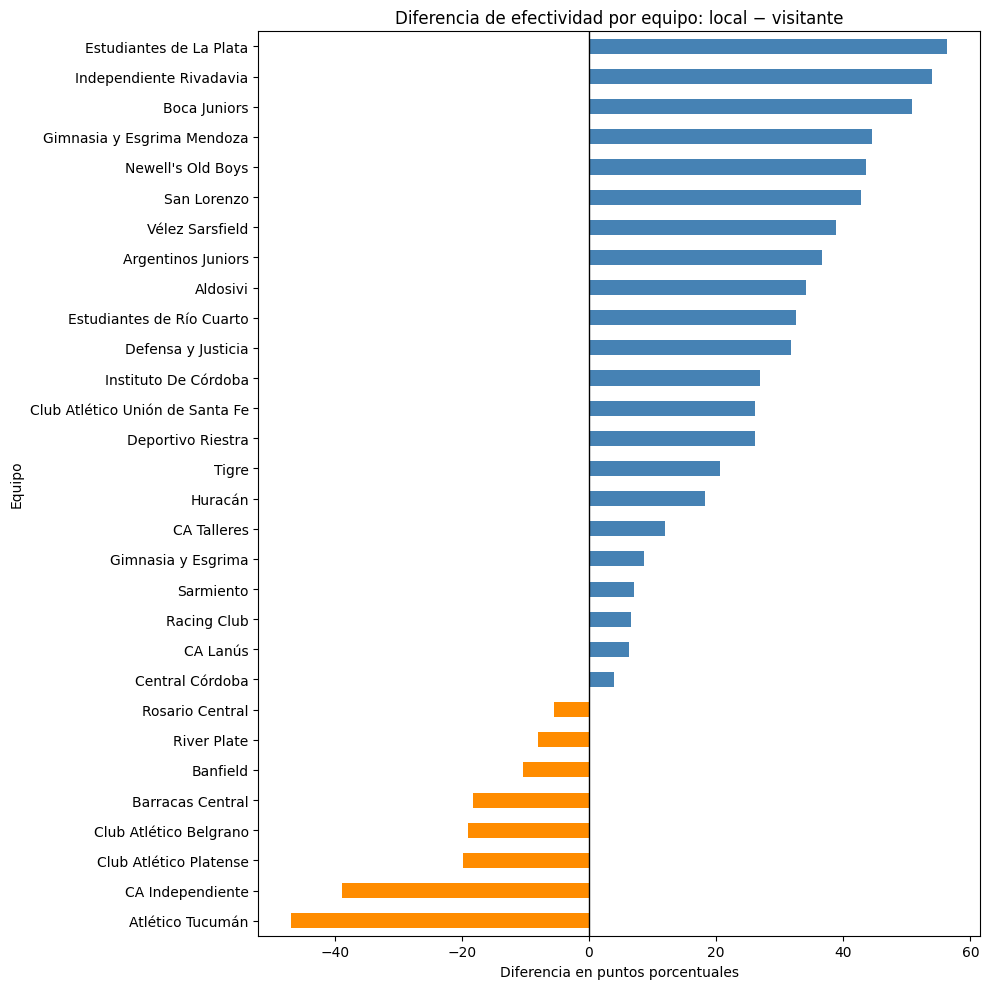

In [ ]:
import matplotlib.pyplot as plt

# Ordenamos para que las diferencias más grandes queden arriba
datos_grafico = por_equipo.sort_values('Diferencia (pp)')

colores = [
    'steelblue' if valor >= 0 else 'darkorange'
    for valor in datos_grafico['Diferencia (pp)']
]

ax = datos_grafico['Diferencia (pp)'].plot(
    kind='barh',
    figsize=(10, 10),
    color=colores
)

ax.axvline(0, color='black', linewidth=1)
ax.set_title('Diferencia de efectividad por equipo: local − visitante')
ax.set_xlabel('Diferencia en puntos porcentuales')
ax.set_ylabel('Equipo')

plt.tight_layout()
plt.savefig('diferencia_efectividad.png', dpi=300, bbox_inches='tight')
plt.show()

# Conclusión: puntos y efectividad según la localía

En los 194 partidos analizados, los locales consiguieron el 52,58 % de los puntos posibles, mientras que los visitantes obtuvieron el 38,14%. Esto muestra una mayor efectividad al jugar de local, con una diferencia de 14,43 puntos porcentuales.

La diferencia varía entre equipos: Estudiantes de La Plata, Independiente Rivadavia y Boca Juniors presentan las mayores ventajas a favor de la localía. En cambio, Atlético Tucumán e Independiente consiguieron mejores resultados como visitantes.

En los partidos analizados, jugar de local se relaciona con una mayor obtención de puntos en general, aunque no ocurre en todos los equipos ni permite afirmar que la localía sea la única causa de los resultados.